# Entrenamiento con GridSearchCV

Continuación del ejercicio de Pipelines de la UT3.



---
## Configuración del entorno y división estratificada

Antes de aplicar cualquier transformación sobre los datos, importamos las librerías necesarias, cargamos el archivo crudo y separamos la variable objetivo `abandono` de las características predictoras. Realizamos una división estratificada (80% train, 20% test).


In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OrdinalEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)


In [4]:
# 1. Carga del dataset crudo
ruta_csv = '0-datasets/clientes_banca_raw.csv' if os.path.exists('0-datasets/clientes_banca_raw.csv') else 'clientes_banca_raw.csv'
df_raw = pd.read_csv(ruta_csv)

# 2. Separación de características predictoras (X) y variable objetivo (y)
X = df_raw.drop(columns=['abandono'])
y = df_raw['abandono']

# 3. Partición Train / Test estratificada (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones de X_train inicial: {X_train.shape}")
print(f"Dimensiones de X_test inicial:  {X_test.shape}")

Dimensiones de X_train inicial: (480, 14)
Dimensiones de X_test inicial:  (120, 14)


## Preprocesamiento

---
### Función para el tratamiento inicial de los datos


In [5]:
# 1. Descarte de columnas no utilizables o con riesgo de data leakage
def _descartar_columnas_no_utilizables(df: pd.DataFrame) -> pd.DataFrame:
    columnas_descarte = ['id_cliente', 'salario_mensual_aprox', 'comentarios_cliente', 'motivo_cancelacion']
    return df.drop(columns=columnas_descarte, errors='ignore')

# 2. Sanitización de centinelas numéricos a NaN
def _sanitizar_centinelas_numericos(df: pd.DataFrame) -> pd.DataFrame:
    if 'edad' in df.columns:
        df.loc[(df['edad'] <= 0) | (df['edad'] > 120), 'edad'] = np.nan
    if 'ingresos_anuales' in df.columns:
        df.loc[df['ingresos_anuales'] <= 0, 'ingresos_anuales'] = np.nan
    if 'saldo_cuenta' in df.columns:
        df['saldo_cuenta'] = df['saldo_cuenta'].replace(-999, np.nan)
    return df

# 3. Sanitización y limpieza de cadenas categóricas
def _sanitizar_categoricos(df: pd.DataFrame) -> pd.DataFrame:
    if 'tipo_cuenta' in df.columns:
        df['tipo_cuenta'] = df['tipo_cuenta'].astype(str).str.strip().str.capitalize()
        df['tipo_cuenta'] = df['tipo_cuenta'].replace({'Desconocido': np.nan, '?': np.nan, 'Nan': np.nan, 'nan': np.nan})

    if 'canal_preferido' in df.columns:
        df['canal_preferido'] = df['canal_preferido'].astype(str).str.strip()
        df['canal_preferido'] = df['canal_preferido'].replace({'???': np.nan, 'Nan': np.nan, 'nan': np.nan})

    if 'nivel_estudios' in df.columns:
        df['nivel_estudios'] = df['nivel_estudios'].astype(str).str.strip().replace({'Nan': np.nan, 'nan': np.nan})

    return df

# 4. Generación de nuevas variables de negocio (Feature Engineering)
def _feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    if 'saldo_cuenta' in df.columns and 'ingresos_anuales' in df.columns:
        df['ratio_saldo_ingresos'] = df['saldo_cuenta'] / (df['ingresos_anuales'] + 1)

    if 'saldo_cuenta' in df.columns and 'num_productos' in df.columns:
        df['saldo_por_producto'] = df['saldo_cuenta'] / df['num_productos']

    if 'edad' in df.columns:
        limites_edad = [0, 30, 55, 120]
        etiquetas_edad = ['Joven', 'Adulto', 'Senior']
        df['grupo_edad'] = pd.cut(df['edad'], bins=limites_edad, labels=etiquetas_edad).astype(str)

    if 'antiguedad_meses' in df.columns:
        df['antiguedad_anios'] = df['antiguedad_meses'] / 12.0
        df = df.drop(columns=['antiguedad_meses'])

    return df

# Función principal orquestadora
def preparar_datos_crudos(df_entrada: pd.DataFrame) -> pd.DataFrame:
    """
    Aplica reglas de negocio deterministas sobre datos crudos llamando a sus subfunciones.
    """
    df = df_entrada.copy()
    df = _descartar_columnas_no_utilizables(df)
    df = _sanitizar_centinelas_numericos(df)
    df = _sanitizar_categoricos(df)
    df = _feature_engineering(df)
    return df


In [6]:
X_train_prep = preparar_datos_crudos(X_train)
X_test_prep = preparar_datos_crudos(X_test)

print(f"Columnas resultantes tras la preparación ({len(X_train_prep.columns)}):")
print(list(X_train_prep.columns))
X_train_prep.head(3)


Columnas resultantes tras la preparación (13):
['edad', 'ingresos_anuales', 'saldo_cuenta', 'nivel_estudios', 'tipo_cuenta', 'nivel_satisfaccion', 'num_productos', 'tiene_tarjeta', 'canal_preferido', 'ratio_saldo_ingresos', 'saldo_por_producto', 'grupo_edad', 'antiguedad_anios']


,edad,ingresos_anuales,saldo_cuenta,nivel_estudios,tipo_cuenta,nivel_satisfaccion,num_productos,tiene_tarjeta,canal_preferido,ratio_saldo_ingresos,saldo_por_producto,grupo_edad,antiguedad_anios
581,65.0,43522.31,5780.88,Grado,Corriente,Medio,1,1,App Movil,0.132823,5780.880,Senior,8.333333
462,40.0,34205.72,14225.97,Secundaria,Corriente,Bajo,2,1,App Movil,0.415882,7112.985,Adulto,9.500000
381,32.0,14066.62,0.00,Secundaria,Corriente,Muy Alto,2,1,Web,0.000000,0.000,Adulto,5.250000


---
### Función de construcción del `ColumnTransformer`

Construimos y ensamblamos la arquitectura de Scikit-learn separando las variables numéricas en dos ramas según sus características:
1. **`num_std` (StandardScaler):** Para variables sin atípicos (`edad`, `num_productos`, `antiguedad_anios`).
2. **`num_rob` (RobustScaler):** Para variables con colas pesadas y valores extremos legítimos (`ingresos_anuales`, `saldo_cuenta`, `ratio_saldo_ingresos`, `saldo_por_producto`).
3. **`ord` (OrdinalEncoder):** Para categóricas con jerarquía natural (`nivel_estudios`, `nivel_satisfaccion`).
4. **`nom` (OneHotEncoder):** Para categóricas sin orden (`tipo_cuenta`, `canal_preferido`, `grupo_edad`).
5. **`bool` (passthrough):** Para la columna binaria `tiene_tarjeta`.


In [7]:
def construir_pipeline_preprocesamiento() -> ColumnTransformer:
    """
    Construye y ensambla el ColumnTransformer con todos los sub-pipelines estadísticos.
    """
    # 1. Columnas numéricas sin atípicos (edad saneada, conteos y antigüedades)
    cols_num_standard = ['edad', 'num_productos', 'antiguedad_anios']

    # 2. Columnas numéricas con valores atípicos o colas pesadas
    cols_num_robust = [
        'ingresos_anuales',
        'saldo_cuenta',
        'ratio_saldo_ingresos',
        'saldo_por_producto'
    ]

    cols_ordinales = ['nivel_estudios', 'nivel_satisfaccion']
    cols_nominales = ['tipo_cuenta', 'canal_preferido', 'grupo_edad']
    cols_passthrough = ['tiene_tarjeta']

    # Sub-pipeline 1: Numérico Estándar (media + StandardScaler)
    pipeline_num_std = Pipeline([
        ('imputador', SimpleImputer(strategy='mean')),
        ('escalador', StandardScaler())
    ])

    # Sub-pipeline 2: Numérico Robusto (mediana + RobustScaler)
    pipeline_num_rob = Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('escalador', RobustScaler())
    ])

    # Sub-pipeline 3: Categórico Ordinal (moda + OrdinalEncoder)
    orden_estudios = ['Primaria', 'Secundaria', 'Grado', 'Master', 'Doctorado']
    orden_satisfaccion = ['Muy Bajo', 'Bajo', 'Medio', 'Alto', 'Muy Alto']

    pipeline_ord = Pipeline([
        ('imputador', SimpleImputer(strategy='most_frequent')),
        ('codificador', OrdinalEncoder(categories=[orden_estudios, orden_satisfaccion])),
        ('escalador', MinMaxScaler())
    ])

    # Sub-pipeline 4: Categórico Nominal (moda + OneHotEncoder)
    pipeline_nom = Pipeline([
        ('imputador', SimpleImputer(strategy='most_frequent')),
        ('codificador', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
    ])

    # Ensamble de ramas en ColumnTransformer
    preprocesador = ColumnTransformer(
        transformers=[
            ('num_std', pipeline_num_std, cols_num_standard),
            ('num_rob', pipeline_num_rob, cols_num_robust),
            ('ord', pipeline_ord, cols_ordinales),
            ('nom', pipeline_nom, cols_nominales),
            ('bool', 'passthrough', cols_passthrough)
        ],
        remainder='drop'
    )

    # Salida en DataFrame de Pandas
    preprocesador.set_output(transform='pandas')

    return preprocesador

preprocesador = construir_pipeline_preprocesamiento()
preprocesador


ColumnTransformer(transformers=[('num_std',
                                 Pipeline(steps=[('imputador', SimpleImputer()),
                                                 ('escalador',
                                                  StandardScaler())]),
                                 ['edad', 'num_productos', 'antiguedad_anios']),
                                ('num_rob',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalador',
                                                  RobustScaler())]),
                                 ['ingresos_anuales', 'saldo_cuenta',
                                  'ratio_saldo_ingresos',
                                  'saldo_por_producto'...
                                                                              'Bajo',
                                                                              'Medio',
                                                                              'Alto',
                                                                              'Muy '
                                                                              'Alto']])),
                                                 ('escalador',
                                                  MinMaxScaler())]),
                                 ['nivel_estudios', 'nivel_satisfaccion']),
                                ('nom',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('codificador',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['tipo_cuenta', 'canal_preferido',
                                  'grupo_edad']),
                                ('bool', 'passthrough', ['tiene_tarjeta'])])

---
### Función de ajuste y serialización

Ajustamos el `ColumnTransformer` sobre `X_train_prep` con `.fit_transform()`, transformamos `X_test_prep` únicamente con `.transform()` y exportamos el artefacto entrenado a disco con `joblib.dump()`.


In [8]:
def ajustar_y_guardar_preprocesador(
    preprocesador: ColumnTransformer,
    X_train_prep: pd.DataFrame,
    X_test_prep: pd.DataFrame,
    ruta_guardado: str = 'preprocesador_banca.joblib'
):
    """
    Ajusta el ColumnTransformer sobre train, transforma test y serializa el objeto en disco.
    """
    print("--> Ajustando preprocesador sobre X_train (fit_transform)...")
    X_train_final = preprocesador.fit_transform(X_train_prep)

    print("--> Aplicando preprocesador sobre X_test (transform)...")
    X_test_final = preprocesador.transform(X_test_prep)

    print(f"Dimensiones de X_train_final: {X_train_final.shape}")
    print(f"Dimensiones de X_test_final:  {X_test_final.shape}")

    # Guardamos el artefacto entrenado
    joblib.dump(preprocesador, ruta_guardado)
    print(f"✅ Preprocesador exportado con éxito en: {ruta_guardado}")

    return X_train_final, X_test_final


### Obtención de X_train y X_test preprocesados

In [9]:
X_train_final, X_test_final = ajustar_y_guardar_preprocesador(
    preprocesador, X_train_prep, X_test_prep
)

X_train_final.head()

--> Ajustando preprocesador sobre X_train (fit_transform)...
--> Aplicando preprocesador sobre X_test (transform)...
Dimensiones de X_train_final: (480, 23)
Dimensiones de X_test_final:  (120, 23)
✅ Preprocesador exportado con éxito en: preprocesador_banca.joblib


,num_std__edad,num_std__num_productos,num_std__antiguedad_anios,num_rob__ingresos_anuales,num_rob__saldo_cuenta,num_rob__ratio_saldo_ingresos,num_rob__saldo_por_producto,ord__nivel_estudios,ord__nivel_satisfaccion,nom__tipo_cuenta_Ahorro,...,nom__canal_preferido_App Movil,nom__canal_preferido_Cajero Antiguo,nom__canal_preferido_Oficina,nom__canal_preferido_Telefono,nom__canal_preferido_Web,nom__grupo_edad_Adulto,nom__grupo_edad_Joven,nom__grupo_edad_Senior,nom__grupo_edad_nan,bool__tiene_tarjeta
581,1.920455,-1.013608,1.142876,0.982371,-0.029182,-0.168256,0.212178,0.50,0.50,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
462,-0.192548,0.181802,1.566423,0.433318,0.551872,0.339799,0.360952,0.25,0.25,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
381,-0.868709,0.181802,0.023502,-0.753538,-0.426929,-0.406655,-0.433449,0.25,1.00,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1
549,-0.446108,-1.013608,-0.369791,-0.128570,-0.049532,-0.007623,0.179146,0.00,0.25,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
128,1.328814,1.377212,-0.127765,0.329618,2.082159,1.610596,0.924145,0.50,0.50,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0


---
## Entrenamiento RandomForest


In [10]:
# 1. Definimos el diccionario con los hiperparámetros a probar
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5]
}

# 2. Configuramos GridSearchCV
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1  # Usa todos los núcleos disponibles del procesador
)

# 3. Ejecutamos la búsqueda sobre los datos de entrenamiento
grid_rf.fit(X_train_final, y_train)

# 4. Consultamos los resultados
print("Mejores hiperparámetros:", grid_rf.best_params_)
print(f"Mejor F1 en validación cruzada: {grid_rf.best_score_:.3f}")

Mejores hiperparámetros: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Mejor F1 en validación cruzada: 0.773


### Métricas

Recuperamos el mejor modelo para calcular las métricas a partir de él.

In [11]:
mejor_modelo_rf = grid_rf.best_estimator_

y_pred = mejor_modelo_rf.predict(X_test_final)

In [12]:
# Lista donde iremos guardando el diccionario de métricas de cada modelo para hacer una tabla final comparativa
resultados_modelos = []

In [13]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

resultados_rf = {
    "Modelo": "Random Forest",
    "Mejores parámetros": str(grid_rf.best_params_),
    "Accuracy": round(acc, 4),
    "Precision": round(prec, 4),
    "Recall": round(rec, 4),
    "F1-score": round(f1, 4)
}

results_df = pd.DataFrame([resultados_rf])

results_df.head()

,Modelo,Mejores parámetros,Accuracy,Precision,Recall,F1-score
0,Random Forest,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",0.725,0.7609,0.614,0.6796


In [14]:
# Guardamos el resumen de este modelo en la lista para la tabla comparativa final
resultados_modelos.append(resultados_rf)

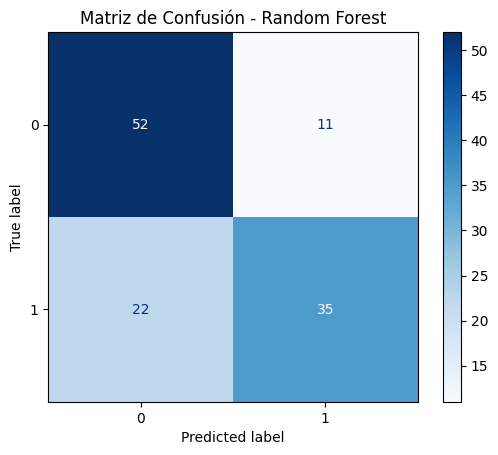

In [15]:
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Matriz de Confusión - Random Forest")
plt.show()

### Análisis over/underfitting

**TODO**: aquí deberías realizar el análisis para detectar qué tal es el rendimiento de tu modelo, es decir, si es capaz de generalizar.

### Exportación del mejor Random Forest

In [16]:
joblib.dump(mejor_modelo_rf, 'modelo_rf.joblib')
print("✅ Modelo RandomForest guardado en: modelo_rf.joblib")

✅ Modelo RandomForest guardado en: modelo_rf.joblib


## Entrenamiento modelo ...

**TODO**: para otro modelo, seguir estructura similar al anterior

## Conclusiones finales

Añadir comparativas de resultados de modelos y conclusión de con cual nos quedaríamos y por qué

In [17]:
resultados_finales = pd.DataFrame(resultados_modelos)

display(resultados_finales)

,Modelo,Mejores parámetros,Accuracy,Precision,Recall,F1-score
0,Random Forest,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",0.725,0.7609,0.614,0.6796
